🟢 < Module 6.2 > Statistical Profiling, Variable Typologies & Transformation Techniques(Pre-EDA)

I considered to put this excercise after Data cleaning because is the previous step before making the EDA.
I added it on Module 4 on Readme.md index because it belongs realisticly to that concept area.

##### 🎯 Context & Objectives

Data cleaning alone is not enough to prepare a dataset for modeling; a Data Scientist must understand the mathematical and structural nature of every feature. In this module, you will formally classify variables into **continuous, discrete, multinomial ordinal, and categorical**, master the transformation techniques required to bridge them (e.g., discretizing continuous metrics into ordinal bins, factorizing ordinal Likert scales into categorical classes, or mapping structural features), **apply standardization and rescaling transformations to continuous variables, and implement outlier detection and treatment strategies to ensure robust modeling inputs**. You will also build basic distribution visualizations to inspect skewness, modality, variance, **and tail behavior** before feature engineering.

##### 📑 Exercise Instructions

###### 1. Syntactic / Algorithmic Level (Variable Typology & Transformation Functions)

Create a Python notebook (`notebooks/06_2_variable_profiling_transformations.ipynb`) that implements the following technical steps:

- **Variable Typology Definition & Profiling**:
    
    - Classify the project variables (`emplrel`, `edulvlb`, `emplno`, `happy`, `lrscale`, `cntry`, `EmployType`) into their exact statistical types: _Continuous_, _Discrete/Count_, _Multinomial Ordinal_, and _Nominal/Categorical_.
        
    - Compute statistical profiling metrics (mean, median, standard deviation, IQR, skewness, **kurtosis**, and unique value counts) for each category.
        
- **Transformation & Discretization Techniques**:
    
    - _Ordinal to Categorical / Binning:_ Use `pd.cut()` or `pd.qcut()` to transform 11-point ordinal scales (e.g., `happy` or `lrscale`) into structured categorical tiers (e.g., Low, Medium, High).
        
    - _Factorization & Mapping:_ Implement `pd.factorize()` and explicit `.map()` dictionaries to convert categorical text columns or custom groupings (like `EmployType`) into clean integer codes without breaking ordinal hierarchies.
        
- **Continuous Variable Transformations**:
    
    - _Rescaling & Standardization:_ Apply **min-max normalization** (`(x - min) / (max - min)`), **z-score standardization** (`(x - mean) / std`), and **log transformation** (`np.log1p()`) to continuous/count variables (e.g., `emplno`, `agea`). Document which transformation is appropriate for each variable type and distribution shape.
        
    - _Monotonic & Non-monotonic:_ Implement **Box-Cox** (`scipy.stats.boxcox`) and **Yeo-Johnson** (`scipy.stats.yeojohnson`) transformations for positively-skewed continuous features. Compare their effect on skewness and kurtosis before and after.
        
    - _Continuous to Discrete (Binning):_ Apply `pd.qcut()` (quantile-based) and `pd.cut()` (fixed-width) to a continuous variable (e.g., `emplno` or `agea`) to create ordinal bins. **Justify the choice of bin edges** (equal-frequency vs. equal-width vs. domain-informed) and document how the binning decision affects downstream model interpretability.
        
- **Outlier Detection & Treatment**:
    
    - _Detection:_ Implement at least **two** outlier detection methods:
        
        1. **IQR method:** Flag observations outside `[Q1 - 1.5×IQR, Q3 + 1.5×IQR]`.
            
        2. **Z-score / Modified Z-score:** Flag observations with `|z| > 3` (or `|modified z| > 3.5` using the MAD-based robust z-score).
            
    - _Treatment:_ For each detected outlier, apply and compare:
        
        1. **Removal:** Drop the observation.
            
        2. **Winsorization (clipping):** Cap values at the 1st and 99th percentiles (`np.clip`).
            
        3. **Imputation:** Replace with the group median (e.g., by `EmployType` or `std_region`).
            
    - _Decision criteria:_ Document **when** each treatment is appropriate (e.g., removal for data entry errors, winsorization for heavy-tailed legitimate variation, imputation for structural missingness). **Never remove outliers without first verifying they are not legitimate observations** (e.g., a self-employed respondent with 400 employees is not an outlier — it is a valid data point).
        

###### 2. Applied / Data Level (Visualizing Distributions & Structural Shifts)

- **Distribution Visualization**:
    
    - Create basic distribution plots (using Matplotlib / Seaborn histograms, KDE curves, and countplots) for key variables like `edulvlb` and `emplno`.
        
    - Visually inspect how the point mass at `0` for wage earners in `emplno` alters the distribution shape compared to self-employed cohorts.
        
    - **Create boxplots (or violin plots) segmented by `EmployType` or `std_region` to visually identify outliers and distributional shifts across subgroups.**
        
- **Transformation Impact Assessment**:
    
    - Compare the descriptive statistics of a variable before and after applying a transformation (e.g., raw 0–10 scale vs. 3-class factorized ordinal; raw `emplno` vs. log-transformed `emplno`). Document when it is mathematically appropriate to treat an ordinal variable as continuous versus categorical.
        
    - **For continuous transformations (log, Box-Cox, z-score): plot the original and transformed distributions side-by-side. Report the change in skewness and kurtosis as a quantitative measure of transformation effectiveness.**
        
- **Outlier Impact Assessment**:
    
    - **Before/after comparison:** For each outlier treatment strategy (removal, winsorization, imputation), report:
        
        - Change in mean, std, IQR, and skewness of the affected variable.
            
        - Number of observations affected (removed, clipped, imputed).
            
        - Visual overlay: original distribution (gray) vs. treated distribution (colored) on the same axis.
            
    - **Decision table:** Summarize in a table which treatment was applied to which variable, how many outliers were affected, and the resulting change in key statistics. Justify the choice per variable.
        

##### 🌐 Official References & Documentation

- **Pandas Categorical Data Guide:** Pandas Working with Categoricals
    
- **Seaborn Distribution Plots:** Seaborn Histplot & KDE Guide
    
- **Scipy Statistical Transformations:** scipy.stats.boxcox & yeojohnson
    

##### 📚 Recommended Manuals & CheatSheets

- **DataCamp Pandas Cheat Sheet:** Pandas Data Manipulation & Transformation
    
- **Statistical Data Types in Machine Learning:** Feature Engineering for Machine Learning (Book Overview)
    
- **Outlier Detection Methods:** [IQR vs. Z-Score vs. Isolation Forest — Comparison](https://towardsdatascience.com/outlier-detection-methods-5749d52d2703)
    

💻 **Your Challenge:** Create the notebook `notebooks/06_2_variable_profiling_transformations.ipynb`, build the statistical profiling summary table, apply the transformation techniques (binning, factorization, **log/Box-Cox, z-score**), **detect and treat outliers with documented justification**, generate the distribution plots for your cleaned dataset, **and produce the before/after comparison tables for both transformations and outlier treatments**. ¡Cuando estés listo, comparte tus resultados o código aquí para revisarlo! 🚀📊

In [1]:
from pathlib import Path
import os
import pandas as pd
import random
#PATHING SCRIPT FOR EVERY EXCERSISE - PROJECT - WORKSPACE
# 1.Literal definition of route pathings(Every user of remote repository must config this pathing in order to find the local repository of his computer)
# My case:
ROOT = Path("/home/josu/Documentos/DataScienceCourse")

# We verify the existence before continue
if not ROOT.exists():
    raise FileNotFoundError(f"❌ The route {ROOT} doesn't exist. Check it.")

# 2. Fix the workspace
os.chdir(ROOT)
print(f"✅ Worskspace enabled!: {os.getcwd()}")

# 3. Define relative pathings to work properly
DATA_TABLES = ROOT / "data" / "raw" / "Tables"

# Let's verify our table folder:
if not DATA_TABLES.exists():
    # If it fails, monitorize the issue: 
    data_dir = ROOT / "data"
    if data_dir.exists():
        print(f"⚠️ the folder 'data' exists but it doesn't have any 'Tables'. 'data' content: {os.listdir(data_dir)}")
    else:
        print(f"⚠️ The folder 'data' doesn't exist on ROOT workspace: {os.listdir(ROOT)}")
    raise FileNotFoundError(f"❌ The tables route {DATA_TABLES} is missing.")

print(f"📂 Tables route detected: {DATA_TABLES}")


✅ Worskspace enabled!: /home/josu/Documentos/DataScienceCourse
📂 Tables route detected: /home/josu/Documentos/DataScienceCourse/data/raw/Tables


In [2]:
import duckdb as db
from dotenv import load_dotenv

load_dotenv()

# Initialize DuckDB connection
con = db.connect()
con.execute("INSTALL postgres; LOAD postgres;")

attach_query = f"""
ATTACH IF NOT EXISTS 'dbname={os.getenv("PGDATABASE")} 
        user={os.getenv("PGUSER")} 
        password={os.getenv("PGPASSWORD")} 
        host={os.getenv("PGHOST")} 
        port={os.getenv("PGPORT")}' 
AS db (TYPE postgres);
"""
con.execute(attach_query)

#Lets prepare a sample dataframe for this excercise
#First of all lets check the rows for every unique value of country and
#Decide how many samples we can get.
print(con.execute("""
    SELECT cntry, COUNT(*) AS n
    FROM db.surveys
    WHERE COLUMNS(*) IS NOT NULL
    GROUP BY cntry
    ORDER BY cntry
""").df())


   cntry     n
0     AT  2197
1     BE  1406
2     BG  1919
3     CH  1226
4     DE  2253
5     EE  1150
6     ES  1635
7     FI  1518
8     FR  1592
9     GB  1561
10    GR  2389
11    HR  1377
12    HU  1925
13    IE  1807
14    IL   783
15    IT  2485
16    NL  1606
17    NO  1238
18    PL  1292
19    PT  1262
20    RS  1367
21    SE  1084
22    SI  1115
23    SK  1312


In [3]:
# 100 rows per country is sufficient for this exercise.
# It affects the analysis (reduced sample size) but not the methodology.

# DuckDB's main advantage here: seamless SQL → Pandas bridge.
# We write a SQL query, get a DataFrame, and chain Pandas methods directly.
#
# Simple example (global random sample):
#   df = con.execute("SELECT ... FROM db.surveys WHERE COLUMNS(*) IS NOT NULL") \
#            .df().sample(n=5000, random_state=42).reset_index(drop=True)
#
# For this case we need a stratified sample: 100 rows per country,
# reproducible via random_state, balanced across all 24 countries.

df_raw = con.execute("""
    SELECT emplno, agea, emplrel, edulvlb, happy, lrscale, cntry, EmployType
    FROM db.surveys
    WHERE COLUMNS(*) IS NOT NULL
""").df()

df_62 = pd.concat([
    g.sample(n=min(100, len(g)), random_state=42)
    for _, g in df_raw.groupby('cntry')
]).reset_index(drop=True)

print(f"Shape: {df_62.shape}")  # → (2400, 8)
del df_raw   

Shape: (2400, 8)


In [4]:
#1.1.A) Classify the project variables (emplrel, edulvlb, emplno, happy, lrscale, cntry, EmployType) 
#into their exact statistical types: Continuous, Discrete/Count, Multinomial Ordinal, and Nominal/Categorical.
# The easiest way is make 2 functions to analyze variables. But we gona make one of them manually to understand
# The process:
# Lets classify the variables with select_dtypes instruction:
import pandas as pd
import numpy as np
num_cols = df_62.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = df_62.select_dtypes(include=['str']).columns.tolist()
#We can also use df.info() instruction for fast checking of this.
print(num_cols,"\n",cat_cols)





['emplno', 'agea', 'emplrel', 'edulvlb', 'happy', 'lrscale'] 
 ['cntry']


In [5]:
# Lets do an exhaustive analisys about "cntry" column. is the only one categorical
# because in this data set about surveys, every categorical value from binaries or ordinal
# are already factorized in to digits as likert scales.
# So our mission is inspect cntry variable and factorize and include them to numerical columns.
# as every categorical, this column is discrete. We can also check
# looking on counts,unique values, unique value counts comparing it to the variable range.
print(df_62['cntry'].count(),"Samples/Rows\n",
      df_62['cntry'].nunique(),"Unique values\n",
      df_62['cntry'].value_counts(),"Quantity of rows of unique values\n",
      df_62['cntry'].isna().sum(),"Quantity of Null values")
#We can also use df_62['cntry'].describe() for more usefull information.




2400 Samples/Rows
 24 Unique values
 cntry
AT    100
BE    100
BG    100
CH    100
DE    100
EE    100
ES    100
FI    100
FR    100
GB    100
GR    100
HR    100
HU    100
IE    100
IL    100
IT    100
NL    100
NO    100
PL    100
PT    100
RS    100
SE    100
SI    100
SK    100
Name: count, dtype: int64 Quantity of rows of unique values
 0 Quantity of Null values


In [6]:
#Lets check the main metrics of country and explain them.
df_62['cntry'].describe()

count     2400
unique      24
top         AT
freq       100
Name: cntry, dtype: object

/tmp/ipykernel_10092/425579281.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=counts, x='count', y='cntry', palette='viridis', legend=False)


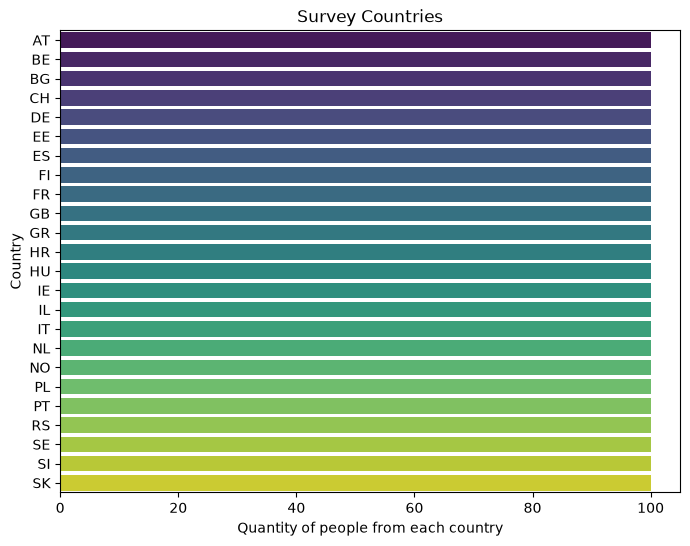

In [7]:
#For being a categorical variable and stratified , our describe doesnt give to much information
#Lets plot it and get more information:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Sort and calculate frecuencies
counts = df_62['cntry'].value_counts().reset_index()
counts.columns = ['cntry', 'count']

plt.figure(figsize=(8, 6))
# 2. Swap the axis being Y axis the country codes and X the number of rows.
sns.barplot(data=counts, x='count', y='cntry', palette='viridis', legend=False)

plt.title('Survey Countries')
plt.xlabel('Quantity of people from each country')
plt.ylabel('Country')
plt.show()

In [11]:
# To end this example, lets factorize ´cntry'column, then we will use 2 functions for analyze every column
# in a easyer way.
df_62['cntry_fc'], x = pd.factorize(df_62['cntry'])
print(df_62['cntry_fc'].unique())

[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23]


🌟 ANÁLISIS 3-EN-1: [EMPLNO] 🌟

--------------------------------------------------
📖 1. DESCRIPCIÓN
--------------------------------------------------
  Familia estadística : NUMERIC
  Subtipo detectado   : DISCRETE_COUNT
  Detalle             : range 0-100, 24 values

--------------------------------------------------
🧮 2. ESTADÍSTICAS Y DIAGNÓSTICO
--------------------------------------------------

  [numeric/discrete_count]  (n=2400, nulls=0)
  Media: 0.2863 | Mediana: 0.0000
  Q1/Q3: 0.0000 / 0.0000 | IQR: 0.0000
  Min/Max: 0.0000 / 100.0000
  % ceros (masa puntual): 96.17%
  ⚠️  WARNING: >50% de los valores son 0. Considera transformación log1p() si usas modelos lineales.

--------------------------------------------------
📊 3. VISUALIZACIÓN ADAPTATIVA
--------------------------------------------------


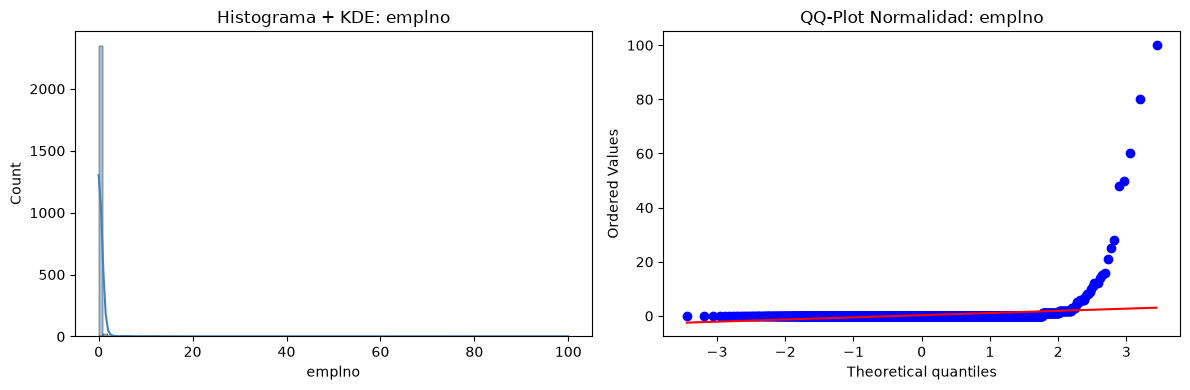

In [13]:
# Well as you can see our new variable stores country codes in a number list.
# In the apparition order.
# Lets get a deep analisis for every variable with our own function.
# You can check this function on src/descriptive_tools.py
from src import ds3on1
ds3on1(df_62, 'emplno', Desc=True, Stat=True, Graph=True)
